# CLUES: Conditional Language Uncertainty via Entropy and Schur Complement

**Authors**: Angelo Ziletti, Leonardo D'Ambrosi

**Paper**: *Disentangling Ambiguity from Instability in Large Language Models: A Clinical Text-to-SQL Case Study*
**arXiv**: [https://arxiv.org/abs/2602.12015](https://arxiv.org/abs/2602.12015)
Accepted at the [8th Clinical NLP Workshop (ClinicalNLP 2026)](https://clinical-nlp.github.io/2026/) at LREC 2026, Palma de Mallorca, Spain.

---

This notebook is a step-by-step tutorial for the **CLUES** framework, which decomposes semantic uncertainty in LLM outputs into two distinct sources:

- **Ambiguity (H_I)**: uncertainty arising from the input question having multiple valid interpretations
- **Instability (H_{R|I})**: uncertainty arising from the model producing inconsistent answers even for a single interpretation

### How CLUES Works

Given a natural language question Q, CLUES follows an **Interpretation-Augmented Generation** protocol:

1. Generate **N distinct interpretations** of the question
2. For each interpretation, generate **M answers** (N×M total answers)
3. Compute pairwise semantic similarity matrices:
   - **W_II** (N×N): interpretation-to-interpretation similarity
   - **W_RR** (NM×NM): answer-to-answer similarity
4. Construct the full block matrix **W** and use the **Schur complement** to decompose entropy
5. Classify into one of **four uncertainty regimes**

| Regime | H(I) | H(R\|I) | Recommended Action |
|--------|-------|---------|-------------------|
| **I. Confident** | Low | Low | Auto-answer |
| **II. Ambiguity** | High | Low | Ask user to clarify |
| **III. Instability** | Low | High | Flag for human review |
| **IV. Compound** | High | High | Clarify + review |

## Setup

In [1]:
import sys
from pathlib import Path

# Add parent directory so clues package is importable
sys.path.insert(0, str(Path.cwd().parent))

import asyncio
import nest_asyncio
nest_asyncio.apply()  # Allow nested event loops in Jupyter

import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import logging

logging.basicConfig(level=logging.WARNING)  # Keep output clean

from clues import UncertaintyDecomposition, GeminiClient
from clues.config import UncertaintyThresholds

print("CLUES loaded successfully.")

CLUES loaded successfully.


## 1. Define an Ambiguous Clinical Question

Consider the question: ***"How many patients over 18 have atopic dermatitis?"***

This question is **ambiguous** because it has multiple valid interpretations:
- Does "over 18" refer to age **at diagnosis** or **current age**?
- Does it mean **first diagnosis** or **any diagnosis**?

We simulate the Interpretation-Augmented Generation pipeline:
- **N = 3** distinct interpretations
- **M = 3** answers per interpretation (9 total)

In [2]:
question = "How many patients over 18 have atopic dermatitis?"

# Three distinct interpretations
interpretations = [
    "Count of unique patients whose age at first diagnosis of atopic dermatitis was > 18.",
    "Count of unique patients currently over 18 with any atopic dermatitis diagnosis.",
    "Count of unique patients over 18 at the time of any atopic dermatitis diagnosis.",
]

# Three answers per interpretation (9 total, N=3, M=3)
answers = [
    # Answers for interpretation 1 (age at first diagnosis)
    "12,847 unique patients had their first atopic dermatitis diagnosis after age 18.",
    "12,851 patients were over 18 at the time of their first atopic dermatitis diagnosis.",
    "12,845 unique patients had first atopic dermatitis diagnosis after the age of 18.",
    # Answers for interpretation 2 (current age, any diagnosis)
    "28,493 unique patients currently over 18 have an atopic dermatitis diagnosis.",
    "28,501 patients aged over 18 have at least one atopic dermatitis diagnosis.",
    "28,490 unique patients over 18 have atopic dermatitis in their history.",
    # Answers for interpretation 3 (age at any diagnosis)
    "21,376 unique patients were over 18 at at least one atopic dermatitis diagnosis.",
    "21,380 patients had atopic dermatitis diagnosed while over 18 years old.",
    "21,372 unique patients had atopic dermatitis diagnosed at age > 18.",
]

# Mapping: which interpretation produced which answer
# [0,0,0, 1,1,1, 2,2,2] = first 3 from I0, next 3 from I1, last 3 from I2
mapping = [0, 0, 0, 1, 1, 1, 2, 2, 2]

print(f"Question: {question}")
print(f"Interpretations (N): {len(interpretations)}")
print(f"Answers per interpretation (M): {len(answers) // len(interpretations)}")
print(f"Total answers (N x M): {len(answers)}")
print()
for i, interp in enumerate(interpretations):
    print(f"  I{i+1}: {interp}")
    for j in range(3):
        print(f"    R{i*3+j+1}: {answers[i*3+j][:70]}...")

Question: How many patients over 18 have atopic dermatitis?
Interpretations (N): 3
Answers per interpretation (M): 3
Total answers (N x M): 9

  I1: Count of unique patients whose age at first diagnosis of atopic dermatitis was > 18.
    R1: 12,847 unique patients had their first atopic dermatitis diagnosis aft...
    R2: 12,851 patients were over 18 at the time of their first atopic dermati...
    R3: 12,845 unique patients had first atopic dermatitis diagnosis after the...
  I2: Count of unique patients currently over 18 with any atopic dermatitis diagnosis.
    R4: 28,493 unique patients currently over 18 have an atopic dermatitis dia...
    R5: 28,501 patients aged over 18 have at least one atopic dermatitis diagn...
    R6: 28,490 unique patients over 18 have atopic dermatitis in their history...
  I3: Count of unique patients over 18 at the time of any atopic dermatitis diagnosis.
    R7: 21,376 unique patients were over 18 at at least one atopic dermatitis ...
    R8: 21,380 pat

## 2. Similarity Matrices (Offline Mode)

In production, CLUES computes semantic similarity via LLM-based bidirectional entailment scoring (see Section 6 for live mode). Here we use pre-computed matrices to demonstrate the math without an API key.

Key observations:
- **W_II** has **low off-diagonal** values → interpretations are **distinct** → high ambiguity
- **W_RR** has a clear **block-diagonal** structure → answers within each interpretation are **consistent** (high similarity), but differ **across** interpretations → low instability

In [3]:
# Pre-computed interpretation similarity (W_II)
w_ii = np.array([
    [1.00, 0.35, 0.55],
    [0.35, 1.00, 0.50],
    [0.55, 0.50, 1.00],
])

# Pre-computed answer similarity (W_RR)
w_rr = np.array([
    [1.00, 0.95, 0.95, 0.15, 0.15, 0.15, 0.30, 0.30, 0.30],
    [0.95, 1.00, 0.95, 0.15, 0.15, 0.15, 0.30, 0.30, 0.30],
    [0.95, 0.95, 1.00, 0.15, 0.15, 0.15, 0.30, 0.30, 0.30],
    [0.15, 0.15, 0.15, 1.00, 0.95, 0.95, 0.35, 0.35, 0.35],
    [0.15, 0.15, 0.15, 0.95, 1.00, 0.95, 0.35, 0.35, 0.35],
    [0.15, 0.15, 0.15, 0.95, 0.95, 1.00, 0.35, 0.35, 0.35],
    [0.30, 0.30, 0.30, 0.35, 0.35, 0.35, 1.00, 0.95, 0.95],
    [0.30, 0.30, 0.30, 0.35, 0.35, 0.35, 0.95, 1.00, 0.95],
    [0.30, 0.30, 0.30, 0.35, 0.35, 0.35, 0.95, 0.95, 1.00],
])

print(f"W_II shape: {w_ii.shape} (N x N)")
print(f"W_RR shape: {w_rr.shape} (NM x NM)")
print(f"\nW_II mean off-diagonal: {np.mean(w_ii[~np.eye(3, dtype=bool)]):.3f} (low = distinct interpretations)")
print(f"W_RR mean within-group:  {np.mean([w_rr[i,j] for i in range(9) for j in range(9) if i!=j and mapping[i]==mapping[j]]):.3f} (high = stable per interpretation)")
print(f"W_RR mean across-group:  {np.mean([w_rr[i,j] for i in range(9) for j in range(9) if mapping[i]!=mapping[j]]):.3f} (low = different across interpretations)")

W_II shape: (3, 3) (N x N)
W_RR shape: (9, 9) (NM x NM)

W_II mean off-diagonal: 0.467 (low = distinct interpretations)
W_RR mean within-group:  0.950 (high = stable per interpretation)
W_RR mean across-group:  0.267 (low = different across interpretations)


### Visualize the Similarity Matrices

The heatmaps show the block structure of the answer similarity matrix — the three 3×3 high-similarity blocks on the diagonal correspond to the three interpretations.

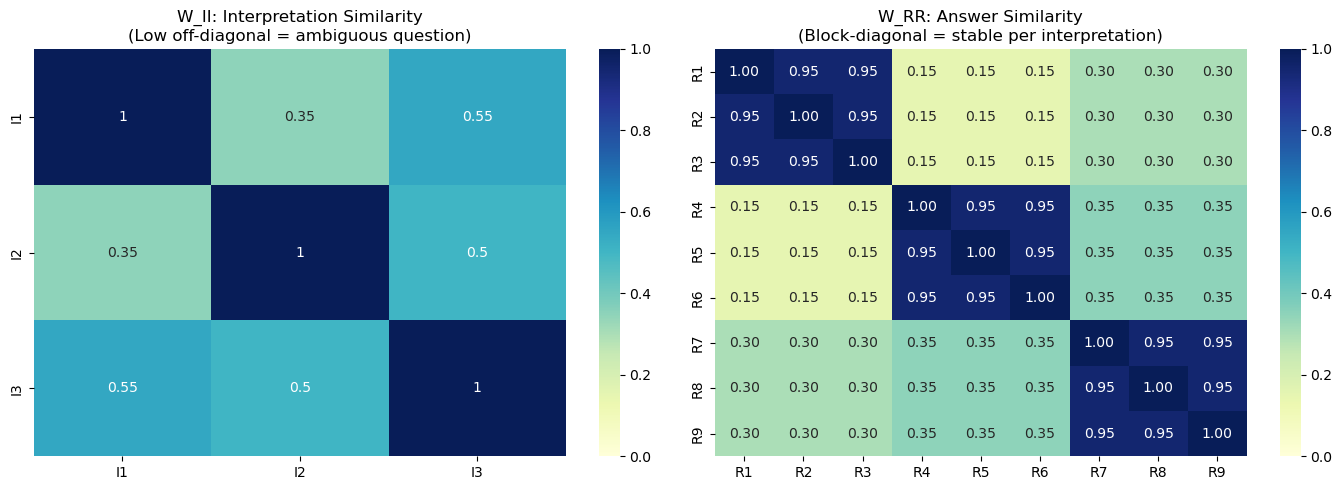

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(w_ii, annot=True, cmap='YlGnBu', vmin=0, vmax=1, ax=axes[0],
            xticklabels=[f'I{i+1}' for i in range(3)],
            yticklabels=[f'I{i+1}' for i in range(3)])
axes[0].set_title('W_II: Interpretation Similarity\n(Low off-diagonal = ambiguous question)')

sns.heatmap(w_rr, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1, ax=axes[1],
            xticklabels=[f'R{i+1}' for i in range(9)],
            yticklabels=[f'R{i+1}' for i in range(9)])
axes[1].set_title('W_RR: Answer Similarity\n(Block-diagonal = stable per interpretation)')

plt.tight_layout()
plt.show()

## 3. Run CLUES Decomposition

The decomposition pipeline:
1. Constructs the block matrix **W = [W_II, W_IR; W_RI, W_RR]** where W_IR is the interpretation-to-answer mapping
2. Computes **H(I)** from the heat kernel of W_II (interpretation entropy)
3. Computes the **Schur complement** S = W_RR - W_RI · inv(W_II + εI) · W_IR
4. Computes **H(R|I)** from the heat kernel of S (conditional entropy, guaranteed ≥ 0)
5. Applies the chain rule: **H(I,R) = H(I) + H(R|I)**

In [5]:
ud = UncertaintyDecomposition(t=10.0)

# Thresholds calibrated for these pre-computed matrices.
# In production, calibrate thresholds on your own data (the paper uses median-based thresholds).
thresholds = UncertaintyThresholds(h_i_threshold=0.005, h_r_given_i_threshold=0.003)

result = asyncio.get_event_loop().run_until_complete(
    ud.compute_decomposed_uncertainty_from_matrices(
        w_ii=w_ii,
        w_rr=w_rr,
        mapping=mapping,
        thresholds=thresholds,
    )
)

ur = result["uncertainty_result"]
e = result["entropies"]

print("CLUES Entropy Decomposition")
print("=" * 40)
print(f"H(I)   = {e['H_I']:.4f}  (interpretation ambiguity)")
print(f"H(R|I) = {e['H(R|I)']:.4f}  (model instability)")
print(f"H(R)   = {e['H_R']:.4f}  (marginal result diversity)")
print(f"H(I,R) = {e['H_QIR']:.4f}  (total uncertainty)")
print()
print(f"Ambiguity contribution:  {ur.ambiguity_contribution:.1%}")
print(f"Instability contribution: {ur.instability_contribution:.1%}")
print()
print(f"Regime: {ur.regime.value.upper()}")
print(f"Action: {ur.recommended_action}")

CLUES Entropy Decomposition
H(I)   = 0.0130  (interpretation ambiguity)
H(R|I) = 0.0020  (model instability)
H(R)   = 0.0396  (marginal result diversity)
H(I,R) = 0.0151  (total uncertainty)

Ambiguity contribution:  86.5%
Instability contribution: 13.5%

Regime: AMBIGUITY
Action: Clarification needed: Question is ambiguous, ask user to clarify.


As expected, the question is classified as **Regime II: Ambiguity** — the interpretations are diverse (high H_I) but the model is stable within each interpretation (low H_R|I). The recommended action is to **clarify the question** with the user.

## 4. Entropy Decomposition Bar Chart

The bar chart shows the relative magnitudes of the entropy components. The dashed purple line represents H(I) + H(R|I), which equals the total joint entropy H(I,R) by the chain rule.

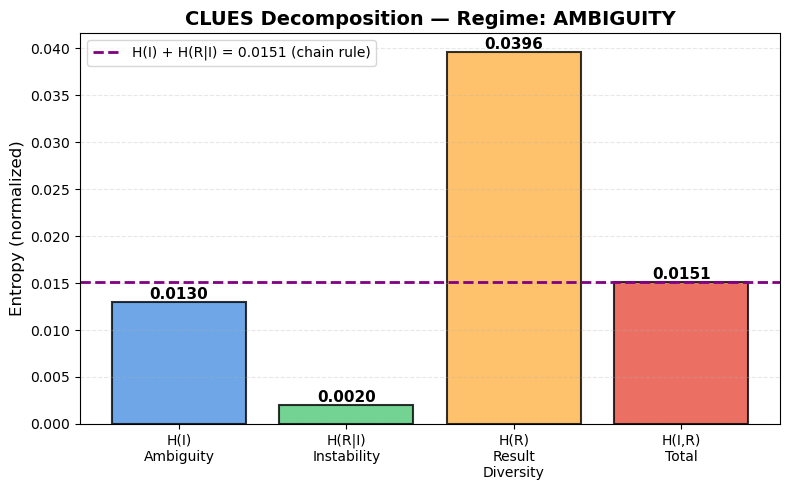

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))

labels = ['H(I)\nAmbiguity', 'H(R|I)\nInstability', 'H(R)\nResult\nDiversity', 'H(I,R)\nTotal']
values = [e['H_I'], e['H(R|I)'], e['H_R'], e['H_QIR']]
colors = ['#4A90E2', '#50C878', '#FFB347', '#E74C3C']

bars = ax.bar(labels, values, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f'{val:.4f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.axhline(y=e['H_I'] + e['H(R|I)'], color='purple', linestyle='--', linewidth=2,
           label=f'H(I) + H(R|I) = {e["H_I"]+e["H(R|I)"]:.4f} (chain rule)')

ax.set_ylabel('Entropy (normalized)', fontsize=12)
ax.set_title(f'CLUES Decomposition — Regime: {ur.regime.value.upper()}', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

## 5. Bipartite Semantic Graph

The core data structure of CLUES is a **bipartite graph** connecting interpretations (I) and results (R):
- **Blue nodes** (I0–I2): the three interpretations
- **Green nodes** (R0–R8): the nine answers
- **Solid edges**: similarity within the same node type (interpretation–interpretation or answer–answer)
- **Red dashed edges**: mapping from interpretations to the answers they produced

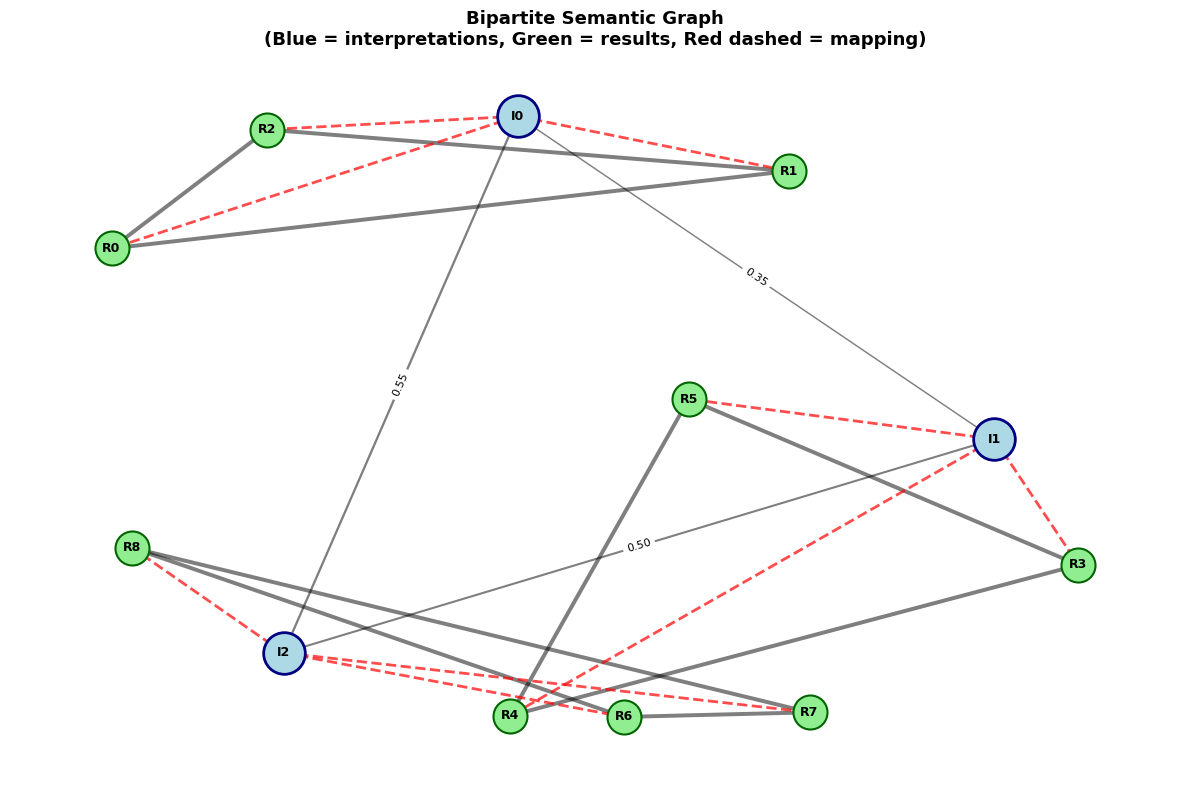

In [7]:
w_ir = result['matrices']['W_IR']

fig, ax = plt.subplots(figsize=(12, 8))

G = nx.Graph()
for i in range(3):
    G.add_node(f'I{i}', type='interpretation')
for i in range(9):
    G.add_node(f'R{i}', type='result')

# Interpretation similarity edges
for i in range(3):
    for j in range(i+1, 3):
        if w_ii[i,j] > 0:
            G.add_edge(f'I{i}', f'I{j}', weight=w_ii[i,j])

# Answer similarity edges (only show strong ones)
for i in range(9):
    for j in range(i+1, 9):
        if w_rr[i,j] > 0.5:
            G.add_edge(f'R{i}', f'R{j}', weight=w_rr[i,j])

# Mapping edges (interpretation -> answers)
for i in range(3):
    for j in range(9):
        if w_ir[i,j] > 0:
            G.add_edge(f'I{i}', f'R{j}', weight=w_ir[i,j])

pos = nx.spring_layout(G, seed=42, k=2)

interp_nodes = [n for n in G.nodes() if n.startswith('I')]
result_nodes = [n for n in G.nodes() if n.startswith('R')]

nx.draw_networkx_nodes(G, pos, nodelist=interp_nodes, node_color='lightblue',
                       node_size=900, edgecolors='navy', linewidths=2, ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=result_nodes, node_color='lightgreen',
                       node_size=600, edgecolors='darkgreen', linewidths=1.5, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=9, font_weight='bold', ax=ax)

sim_edges = [(u,v) for u,v in G.edges() if u[0]==v[0]]
map_edges = [(u,v) for u,v in G.edges() if u[0]!=v[0]]

sim_weights = [G[u][v]['weight'] * 3 for u,v in sim_edges]
nx.draw_networkx_edges(G, pos, edgelist=sim_edges, width=sim_weights, alpha=0.5, ax=ax)
nx.draw_networkx_edges(G, pos, edgelist=map_edges, edge_color='red',
                       style='dashed', alpha=0.7, width=2, ax=ax)

# Add edge labels for interpretation similarities
ii_edge_labels = {(u,v): f'{G[u][v]["weight"]:.2f}' for u,v in sim_edges if u.startswith('I')}
nx.draw_networkx_edge_labels(G, pos, edge_labels=ii_edge_labels, font_size=8, ax=ax)

ax.set_title('Bipartite Semantic Graph\n'
             '(Blue = interpretations, Green = results, Red dashed = mapping)',
             fontsize=13, fontweight='bold')
ax.axis('off')
plt.tight_layout()
plt.show()

Notice how the answer nodes form **three distinct clusters** (R0–R2, R3–R5, R6–R8), each connected to its corresponding interpretation. This structure drives the high ambiguity and low instability in the decomposition.

## 6. Full Block Matrix W

The full system similarity matrix combines all submatrices:

```
W = [ W_II   W_IR ]
    [ W_RI   W_RR ]
```

The red lines in the heatmap separate the interpretation block (top-left 3×3) from the result block (bottom-right 9×9).

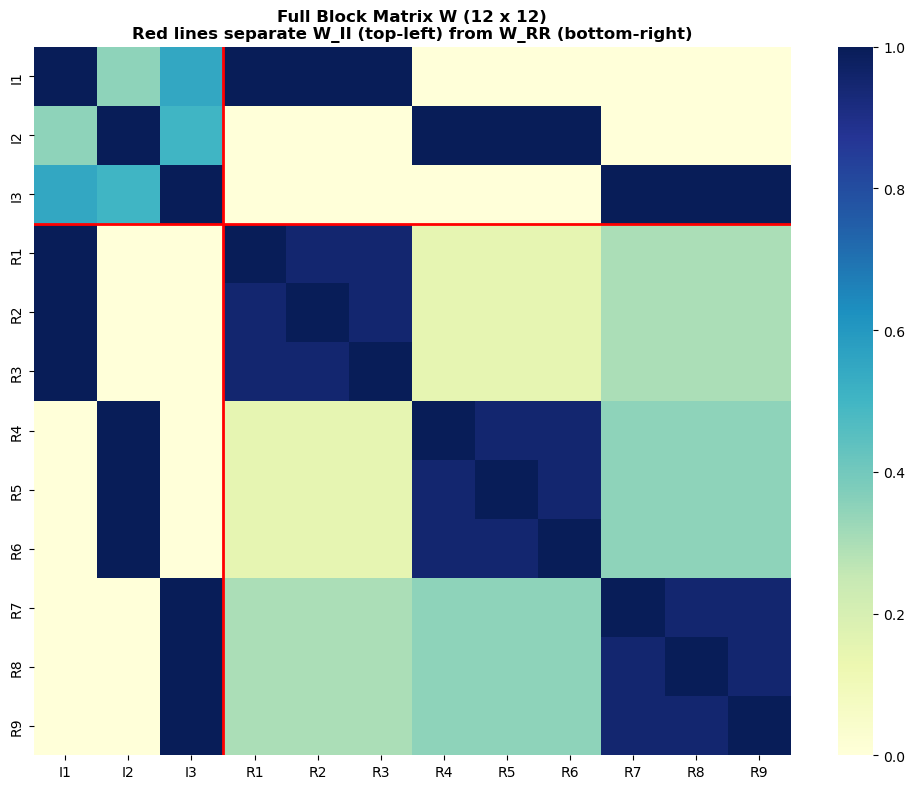

In [8]:
w_full = result['matrices']['W_full']
n_i = len(interpretations)
n_r = len(answers)

fig, ax = plt.subplots(figsize=(10, 8))
full_labels = [f'I{i+1}' for i in range(n_i)] + [f'R{i+1}' for i in range(n_r)]

sns.heatmap(w_full, annot=False, cmap='YlGnBu', vmin=0, vmax=1,
            xticklabels=full_labels, yticklabels=full_labels, ax=ax)
ax.axhline(y=n_i, color='r', linestyle='-', linewidth=2)
ax.axvline(x=n_i, color='r', linestyle='-', linewidth=2)

ax.set_title(f'Full Block Matrix W ({n_i + n_r} x {n_i + n_r})\n'
             f'Red lines separate W_II (top-left) from W_RR (bottom-right)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## 7. Comparing All Three Uncertainty Regimes

Now let's run CLUES on three different clinical questions that demonstrate three different regimes:

1. **Ambiguous** (Regime II): *"How many patients over 18 have atopic dermatitis?"* — multiple valid interpretations, but stable answers within each
2. **Confident** (Regime I): *"Total count of unique female patients aged 18-55 with a first endometriosis diagnosis between 2015-2020?"* — clear question, consistent answers
3. **Unstable** (Regime III): *"List the top 5 most prescribed medications for hypertension patients."* — similar interpretations, but model produces varying answers (different orderings, different medications)

In [9]:
# Define the Confident and Unstable examples (Ambiguous was defined above)
examples = {
    "Ambiguous": {
        "question": question,
        "w_ii": w_ii,
        "w_rr": w_rr,
    },
    "Confident": {
        "question": "What is the total count of unique female patients aged 18-55 with a first diagnosis of endometriosis between 2015 and 2020?",
        "w_ii": np.array([
            [1.00, 0.95, 0.93],
            [0.95, 1.00, 0.94],
            [0.93, 0.94, 1.00],
        ]),
        "w_rr": np.array([
            [1.00, 0.98, 0.95, 0.98, 0.97, 0.94, 0.98, 0.95, 0.97],
            [0.98, 1.00, 0.95, 0.97, 0.98, 0.94, 0.97, 0.95, 0.98],
            [0.95, 0.95, 1.00, 0.95, 0.95, 0.93, 0.95, 0.97, 0.95],
            [0.98, 0.97, 0.95, 1.00, 0.97, 0.94, 0.98, 0.95, 0.97],
            [0.97, 0.98, 0.95, 0.97, 1.00, 0.94, 0.97, 0.95, 0.98],
            [0.94, 0.94, 0.93, 0.94, 0.94, 1.00, 0.94, 0.93, 0.94],
            [0.98, 0.97, 0.95, 0.98, 0.97, 0.94, 1.00, 0.95, 0.97],
            [0.95, 0.95, 0.97, 0.95, 0.95, 0.93, 0.95, 1.00, 0.95],
            [0.97, 0.98, 0.95, 0.97, 0.98, 0.94, 0.97, 0.95, 1.00],
        ]),
    },
    "Unstable": {
        "question": "List the top 5 most prescribed medications for hypertension patients.",
        "w_ii": np.array([
            [1.00, 0.80, 0.75],
            [0.80, 1.00, 0.78],
            [0.75, 0.78, 1.00],
        ]),
        "w_rr": np.array([
            [1.00, 0.60, 0.65, 0.45, 0.40, 0.48, 0.50, 0.42, 0.52],
            [0.60, 1.00, 0.58, 0.42, 0.50, 0.45, 0.45, 0.48, 0.47],
            [0.65, 0.58, 1.00, 0.48, 0.42, 0.50, 0.52, 0.45, 0.55],
            [0.45, 0.42, 0.48, 1.00, 0.55, 0.60, 0.50, 0.48, 0.52],
            [0.40, 0.50, 0.42, 0.55, 1.00, 0.58, 0.45, 0.52, 0.48],
            [0.48, 0.45, 0.50, 0.60, 0.58, 1.00, 0.52, 0.50, 0.55],
            [0.50, 0.45, 0.52, 0.50, 0.45, 0.52, 1.00, 0.55, 0.62],
            [0.42, 0.48, 0.45, 0.48, 0.52, 0.50, 0.55, 1.00, 0.58],
            [0.52, 0.47, 0.55, 0.52, 0.48, 0.55, 0.62, 0.58, 1.00],
        ]),
    },
}

# Suppress PSD projection warnings for cleaner output
logging.getLogger("clues.schur").setLevel(logging.ERROR)

# Run CLUES on all three
results_all = {}
for name, ex in examples.items():
    r = asyncio.get_event_loop().run_until_complete(
        ud.compute_decomposed_uncertainty_from_matrices(
            w_ii=ex["w_ii"], w_rr=ex["w_rr"], mapping=mapping, thresholds=thresholds,
        )
    )
    results_all[name] = r
    ent = r["entropies"]
    ur_ex = r["uncertainty_result"]
    print(f"--- {name.upper()} ---")
    print(f"  Q: {ex['question'][:80]}...")
    print(f"  H(I)={ent['H_I']:.4f}  H(R|I)={ent['H(R|I)']:.4f}  "
          f"Regime: {ur_ex.regime.value.upper()}")
    print(f"  Action: {ur_ex.recommended_action}")
    print()

# Restore logging level
logging.getLogger("clues.schur").setLevel(logging.WARNING)

--- AMBIGUOUS ---
  Q: How many patients over 18 have atopic dermatitis?...
  H(I)=0.0130  H(R|I)=0.0020  Regime: AMBIGUITY
  Action: Clarification needed: Question is ambiguous, ask user to clarify.

--- CONFIDENT ---
  Q: What is the total count of unique female patients aged 18-55 with a first diagno...
  H(I)=0.0011  H(R|I)=0.0019  Regime: CONFIDENT
  Action: Auto-answer: High confidence, proceed with response.

--- UNSTABLE ---
  Q: List the top 5 most prescribed medications for hypertension patients....
  H(I)=0.0020  H(R|I)=0.0040  Regime: INSTABILITY
  Action: Human review: Model unstable, flag for expert review.



### Visualize the Three Regimes

Let's compare the answer similarity matrices (W_RR) and entropy decompositions across all three examples. The structural differences in the heatmaps directly explain the regime classification:

- **Ambiguous**: Strong block-diagonal structure (clusters of similar answers per interpretation, but different across interpretations)
- **Confident**: Uniformly high similarity everywhere (all answers agree regardless of interpretation)
- **Unstable**: Low similarity everywhere, including within blocks (model produces different answers even for the same interpretation)

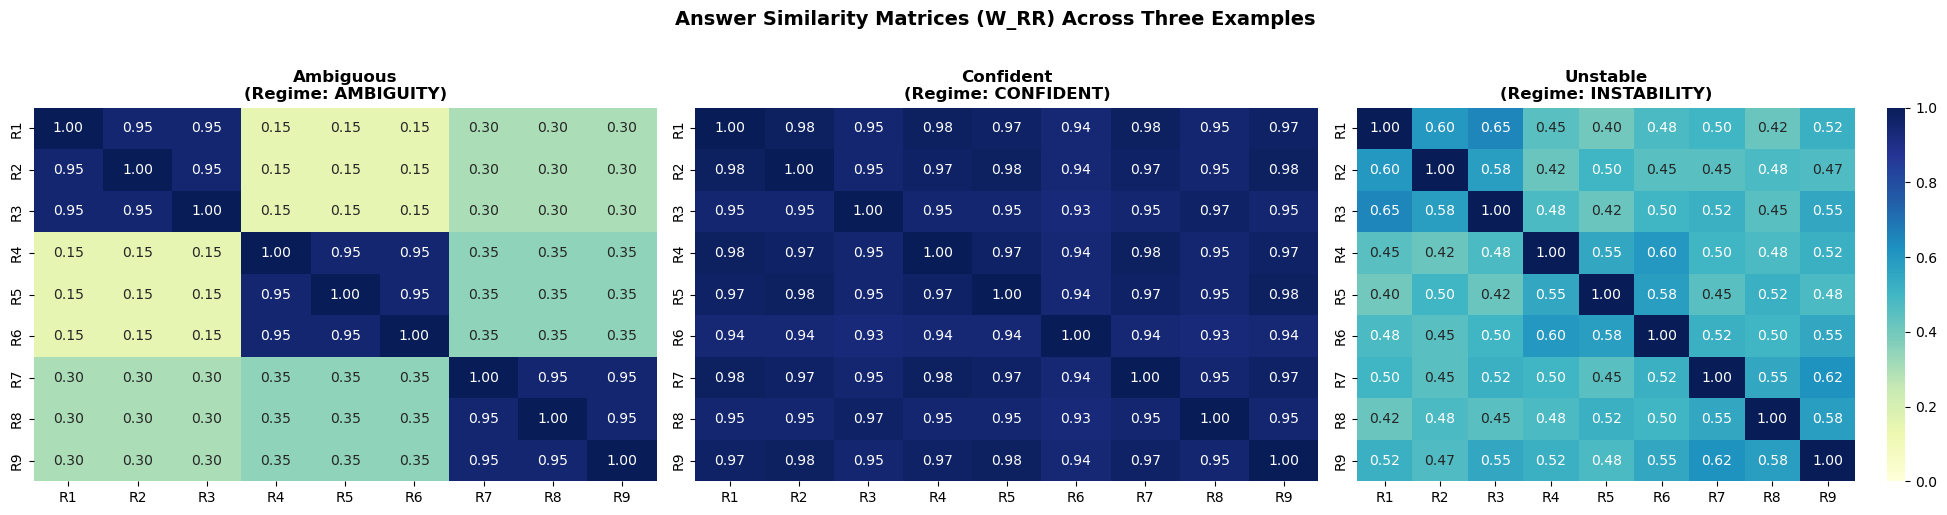

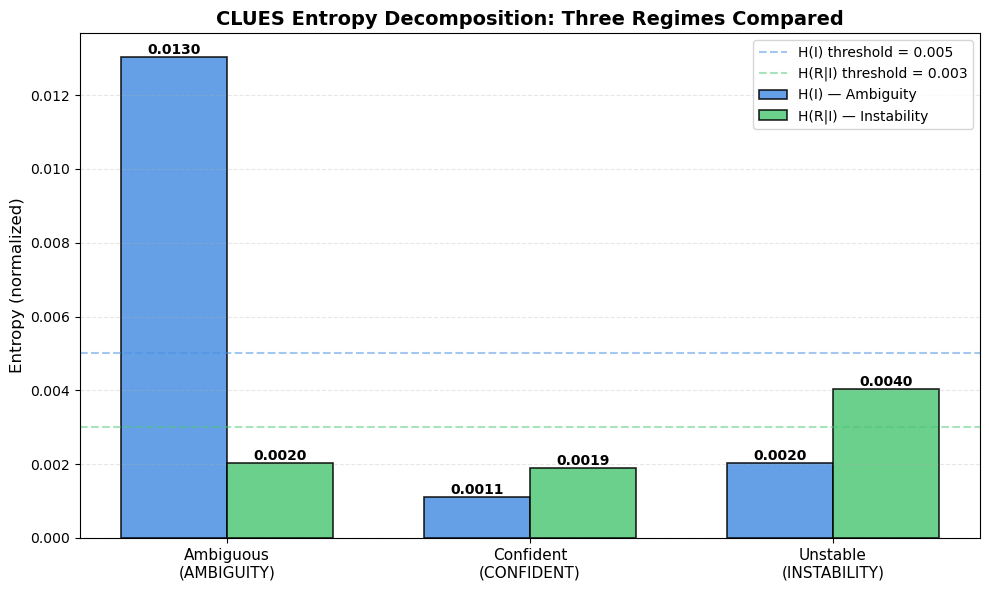


Summary Table
Example      H(I)       H(R|I)     Regime          Action
---------------------------------------------------------------------------
Ambiguous    0.0130     0.0020     AMBIGUITY       Clarification needed: Question is ambiguous, ask user to clarify.
Confident    0.0011     0.0019     CONFIDENT       Auto-answer: High confidence, proceed with response.
Unstable     0.0020     0.0040     INSTABILITY     Human review: Model unstable, flag for expert review.


In [10]:
# --- W_RR heatmaps side by side ---
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for idx, (name, ex) in enumerate(examples.items()):
    r = results_all[name]
    regime = r["uncertainty_result"].regime.value.upper()
    sns.heatmap(ex["w_rr"], annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1,
                ax=axes[idx], cbar=(idx == 2),
                xticklabels=[f'R{i+1}' for i in range(9)],
                yticklabels=[f'R{i+1}' for i in range(9)])
    axes[idx].set_title(f'{name}\n(Regime: {regime})', fontsize=12, fontweight='bold')

plt.suptitle('Answer Similarity Matrices (W_RR) Across Three Examples', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# --- Grouped bar chart of entropy components ---
fig, ax = plt.subplots(figsize=(10, 6))

regime_names = list(results_all.keys())
h_i_vals = [results_all[n]["entropies"]["H_I"] for n in regime_names]
h_ri_vals = [results_all[n]["entropies"]["H(R|I)"] for n in regime_names]
regimes = [results_all[n]["uncertainty_result"].regime.value.upper() for n in regime_names]

x = np.arange(len(regime_names))
width = 0.35

bars1 = ax.bar(x - width/2, h_i_vals, width, label='H(I) — Ambiguity',
               color='#4A90E2', alpha=0.85, edgecolor='black', linewidth=1.2)
bars2 = ax.bar(x + width/2, h_ri_vals, width, label='H(R|I) — Instability',
               color='#50C878', alpha=0.85, edgecolor='black', linewidth=1.2)

# Add value labels on bars
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

# Add threshold lines
ax.axhline(y=thresholds.h_i_threshold, color='#4A90E2', linestyle='--', alpha=0.5,
           label=f'H(I) threshold = {thresholds.h_i_threshold}')
ax.axhline(y=thresholds.h_r_given_i_threshold, color='#50C878', linestyle='--', alpha=0.5,
           label=f'H(R|I) threshold = {thresholds.h_r_given_i_threshold}')

ax.set_xticks(x)
ax.set_xticklabels([f'{name}\n({regime})' for name, regime in zip(regime_names, regimes)], fontsize=11)
ax.set_ylabel('Entropy (normalized)', fontsize=12)
ax.set_title('CLUES Entropy Decomposition: Three Regimes Compared', fontsize=14, fontweight='bold')
ax.legend(fontsize=10, loc='upper right')
ax.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

# Print summary table
print("\nSummary Table")
print("=" * 75)
print(f"{'Example':<12} {'H(I)':<10} {'H(R|I)':<10} {'Regime':<15} {'Action'}")
print("-" * 75)
for name in regime_names:
    ent = results_all[name]["entropies"]
    ur_ex = results_all[name]["uncertainty_result"]
    print(f"{name:<12} {ent['H_I']:<10.4f} {ent['H(R|I)']:<10.4f} {ur_ex.regime.value.upper():<15} {ur_ex.recommended_action}")

## 8. Summary: The Four Uncertainty Regimes

CLUES classifies each question into one of four regimes based on the entropy decomposition:

| Regime | H(I) | H(R\|I) | Meaning | Action |
|--------|-------|---------|---------|--------|
| **I. Confident** | Low | Low | Clear question, consistent answers | Auto-answer |
| **II. Ambiguity** | High | Low | Ambiguous question, stable model | Ask user to clarify |
| **III. Instability** | Low | High | Clear question, inconsistent model | Flag for human review |
| **IV. Compound** | High | High | Ambiguous + unstable | Clarify + review |

This decomposition enables **targeted interventions**: instead of treating all uncertainty the same, the system can ask for clarification when the question is ambiguous or escalate to a human when the model is unreliable.

For more details, see the full paper at [ClinicalNLP 2026](https://clinical-nlp.github.io/2026/).

---

## Citation

If you use CLUES in your research, please cite:

```bibtex
@misc{ziletti2026disentanglingambiguityinstabilitylarge,
      title={Disentangling Ambiguity from Instability in Large Language Models: A Clinical Text-to-SQL Case Study},
      author={Angelo Ziletti and Leonardo D'Ambrosi},
      year={2026},
      eprint={2602.12015},
      archivePrefix={arXiv},
      primaryClass={cs.CL},
      url={https://arxiv.org/abs/2602.12015},
}
```